# EDA: Hotel booking demand

**Цель ноутбука** : оценить **качество данных** датасета бронирований двух португальских отелей (структуру, полноту, целостность, выбросы и аномалии). 

**Данные.** [Hotel booking demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand) (Antonio, Almeida, Nunes, *Data in Brief*, 2019): бронирования City Hotel (Лиссабон) и Resort Hotel (Алгарве) с датой заезда с 01.07.2015 по 31.08.2017. Данные загружаются и приводятся к типам скриптом `data_loader.py`, здесь читается `hotel_bookings.parquet`. Перед запуском ноутбука нужно один раз выполнить из корня репозитория `uv run python data_loader.py`.

**План:**
1. Загрузка данных
2. Структура данных
3. Полнота: пропуски, в том числе скрытые
4. Целостность: дубликаты и логические проверки
5. Выбросы и аномалии
6. Категориальные признаки
7. Корреляции
8. Метрики качества данных
9. Выводы

## 1. Загрузка данных

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", None)  # показывать все столбцы
pd.set_option("display.float_format", "{:.2f}".format)  # 2 знака после запятой

# файл создаёт data_loader.py (запустить из корня: uv run python data_loader.py)
df = pd.read_parquet("../hotel_bookings.parquet")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,False,342,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,False,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,False,737,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,False,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,False,7,2015,July,27,1,0,1,1,0,0,BB,GBR,Direct,Direct,False,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,False,13,2015,July,27,1,0,1,1,0,0,BB,GBR,Corporate,Corporate,False,0,0,A,A,0,No Deposit,304,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,False,14,2015,July,27,1,0,2,2,0,0,BB,GBR,Online TA,TA/TO,False,0,0,A,A,0,No Deposit,240,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03


Parquet сохраняет типы, поэтому столбцы сразу приходят приведёнными (category, bool, int16, datetime). При чтении исходного CSV пропуски, записанные строкой `NULL`, уже превращены в настоящие `NaN`.

## 2. Структура данных

In [2]:
print(f"Строк: {df.shape[0]:,}, столбцов: {df.shape[1]}")
print(f"Память: {df.memory_usage(deep=True).sum() / 1024**2:.1f} МБ")
df.dtypes.astype(str).value_counts()

Строк: 119,390, столбцов: 32
Память: 6.8 МБ


int16             14
category          13
bool               2
Int8               1
float32            1
datetime64[us]     1
Name: count, dtype: int64

In [3]:
# сводка по каждому столбцу: тип, число уникальных значений, доля пропусков, пример
summary = pd.DataFrame({
    "тип": df.dtypes,
    "уникальных": df.nunique(),
    "пропусков_%": df.isna().mean() * 100,
})
summary

,тип,уникальных,пропусков_%
hotel,category,2,0.00
is_canceled,bool,2,0.00
lead_time,int16,479,0.00
arrival_date_year,int16,3,0.00
arrival_date_month,category,12,0.00
arrival_date_week_number,int16,53,0.00
arrival_date_day_of_month,int16,31,0.00
stays_in_weekend_nights,int16,17,0.00
stays_in_week_nights,int16,35,0.00
adults,int16,14,0.00


**Что видно по структуре:**

- 119 390 строк × 32 признака.
- Признаки разных типов: **категориальные** (отель, месяц, страна, тип питания, сегмент, канал, типы номеров, тип депозита, тип клиента, статус), **бинарные** (`is_canceled`, `is_repeated_guest`), **числовые дискретные** (число ночей, гостей, изменений брони), **числовые непрерывные** (`adr` — средняя цена за ночь), **дата** (`reservation_status_date`).
- **Высокая кардинальность**: `country` (177 стран), `agent` (~330 агентов), `company` (~350 компаний). Для моделей такие признаки придётся кодировать особым образом или группировать редкие значения.
- **Дата заезда разбита на 4 столбца** (год, месяц словом, номер недели, день) — для анализа удобнее собрать её в одну дату.
- В датасете **нет идентификатора бронирования** — это важно для оценки дубликатов.

In [4]:
# собираем дату заезда в один столбец — пригодится для проверок
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-"
    + df["arrival_date_month"].astype(str) + "-"
    + df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",
)
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"].fillna(0) + df["babies"]

print("Период заездов:", df["arrival_date"].min().date(), "—", df["arrival_date"].max().date())

Период заездов: 2015-07-01 — 2017-08-31


## 3. Полнота: пропуски

In [5]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_table = pd.DataFrame({"пропусков": missing, "доля_%": missing / len(df) * 100})
missing_table

,пропусков,доля_%
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


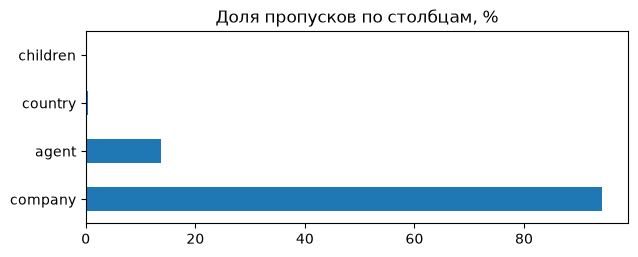

In [6]:
missing_table["доля_%"].plot.barh(figsize=(7, 2.5), title="Доля пропусков по столбцам, %")
plt.show()

**Анализ явных пропусков:**

- `company` — **94%** пропусков. Это не ошибка сбора: пропуск означает «бронь не оплачивается компанией». Как самостоятельный признак столбец почти бесполезен.
- `agent` — **13.7%**: бронь сделана без турагента (напрямую). Пропуск тоже содержательный — его стоит заменить категорией вроде `no_agent`, а не удалять строки.
- `country` — **0.4%** (488 строк): страна гостя неизвестна. Доля мала, можно заменить на `Unknown`.
- `children` — 4 пропуска, ничтожно мало; логично заменить на 0.

Итог: явных пропусков немного, и почти все объяснимы **смыслом признака**, а не потерей данных.

### 3.1. Скрытые пропуски

In [7]:
# значения, которые по смыслу означают «неизвестно», но не являются NaN
print("meal = Undefined:", (df["meal"] == "Undefined").sum())
print("market_segment = Undefined:", (df["market_segment"] == "Undefined").sum())
print("distribution_channel = Undefined:", (df["distribution_channel"] == "Undefined").sum())

meal = Undefined: 1169
market_segment = Undefined: 2
distribution_channel = Undefined: 5


- В `meal` есть **`Undefined` (1 169 строк)**. По описанию авторов датасета `Undefined` и `SC` (self catering) означают одно и то же — «без питания». Это **несогласованная кодировка** одной категории: перед анализом их стоит объединить.
- `Undefined` в `market_segment` (2) и `distribution_channel` (5) — фактически пропуски, замаскированные под категорию.

## 4. Целостность

### 4.1. Дубликаты

In [8]:
n_dup = df.duplicated().sum()
print("Полных дубликатов:", n_dup, "| доля:", round(n_dup / len(df) * 100, 1), "%")
df[df.duplicated()]["hotel"].value_counts()

Полных дубликатов: 31994 | доля: 26.8 %


hotel
City Hotel      25902
Resort Hotel     6092
Name: count, dtype: int64

**Почти 27% строк — полные дубликаты.** Интерпретировать это однозначно нельзя: в датасете нет ID бронирования, поэтому одинаковые строки могут быть как **технической ошибкой выгрузки**, так и **реальными отдельными бронями** (например, группа заказала несколько одинаковых номеров на одни даты через одного агента). Большинство дубликатов приходится на City Hotel, где много групповых броней через турагентства.

Вывод: удалять дубликаты «вслепую» нельзя — это может исказить объём спроса. Решение зависит от задачи; в любом случае это главный риск качества данного датасета.

### 4.2. Логические проверки

In [9]:
print("0 гостей:", (df["total_guests"] == 0).sum())
print("0 ночей:", (df["total_nights"] == 0).sum())
print("нет взрослых, но есть дети:", ((df["adults"] == 0) & (df["total_guests"] > 0)).sum())
print("adr < 0:", (df["adr"] < 0).sum())
print("adr = 0 не в сегменте Complementary:", ((df["adr"] == 0) & (df["market_segment"] != "Complementary")).sum())

0 гостей: 180
0 ночей: 715
нет взрослых, но есть дети: 223
adr < 0: 1
adr = 0 не в сегменте Complementary: 1279


- **180 броней без гостей** (0 взрослых, детей и младенцев) — невозможная ситуация, явная ошибка данных.
- **715 броней на 0 ночей** — может быть «дневным» использованием номера, но выглядит подозрительно и требует проверки у владельца данных.
- **223 брони только с детьми, без взрослых** — для отеля маловероятно; скорее ошибка ввода.
- **Отрицательная цена** — 1 строка, явная ошибка. **Нулевая цена** встречается и вне сегмента Complementary (бесплатные номера) — 1 279 строк, они тоже подозрительны.

In [10]:
# согласованность двух столбцов, описывающих исход брони
pd.crosstab(df["is_canceled"], df["reservation_status"])

reservation_status,Canceled,Check-Out,No-Show
is_canceled,,,
False,0,75166,0
True,43017,0,1207


`is_canceled` и `reservation_status` **полностью согласованы**: `True` ↔ Canceled/No-Show, `False` ↔ Check-Out. Противоречий нет — но это значит, что `reservation_status` (и его дата) **дублируют целевую переменную**. При построении модели отмен их нужно исключать, иначе будет утечка данных (data leakage).

In [11]:
# для выехавших гостей дата статуса должна совпадать с датой выезда = заезд + число ночей
checkout = df[df["reservation_status"] == "Check-Out"]
expected = checkout["arrival_date"] + pd.to_timedelta(checkout["total_nights"], unit="D")
print("Check-Out: дата статуса не совпадает с датой выезда:", (checkout["reservation_status_date"] != expected).sum())

# отмена не может быть зарегистрирована позже даты заезда
canceled = df[df["reservation_status"] == "Canceled"]
print("Отмена после даты заезда:", (canceled["reservation_status_date"] > canceled["arrival_date"]).sum())

Check-Out: дата статуса не совпадает с датой выезда: 27
Отмена после даты заезда: 0


Даты в целом согласованы: для выехавших гостей расхождение даты выезда — лишь в 27 строках из 75 тыс., а отмен «задним числом» нет. Это хороший признак качества.

In [12]:
# номер недели в датасете vs ISO-неделя, посчитанная по дате
week_diff = df["arrival_date_week_number"] - df["arrival_date"].dt.isocalendar().week.astype(int)
pd.crosstab(df["arrival_date_year"], week_diff)

col_0,-52,-51,0,1,2
arrival_date_year,,,,,
2015,0,0,19960,2036,0
2016,227,62,0,49686,6732
2017,0,128,35376,5183,0


**`arrival_date_week_number` не совпадает со стандартной ISO-неделей** более чем у половины строк (~54%): расхождение на 1–2 недели, причём разное по годам (в 2016 году сдвинуты почти все строки). Значит, номер недели в источнике считался по своей, неизвестной нам методике. Признак лучше **пересчитать из даты** или не использовать, иначе сравнение недель между годами будет некорректным.

### 4.3. Покрытие по времени

In [13]:
coverage = pd.crosstab(df["arrival_date"].dt.year, df["arrival_date"].dt.month)
coverage

arrival_date,1,2,3,4,5,6,7,8,9,10,11,12
arrival_date,,,,,,,,,,,,
2015,0,0,0,0,0,0,2776,3889,5114,4957,2340,2920
2016,2248,3891,4824,5428,5478,5292,4572,5063,5394,6203,4454,3860
2017,3681,4177,4970,5661,6313,5647,5313,4925,0,0,0,0


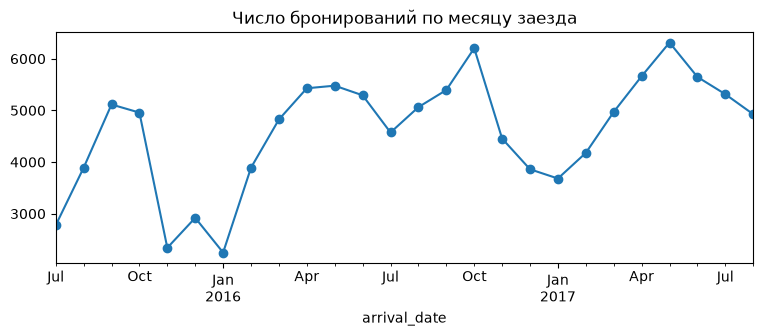

In [14]:
monthly = df.groupby(df["arrival_date"].dt.to_period("M")).size()
monthly.plot(figsize=(9, 3), marker="o", title="Число бронирований по месяцу заезда")
plt.show()

Полностью покрыт только **2016 год**: 2015 начинается с июля, 2017 заканчивается августом. Поэтому **нельзя сравнивать годы целиком** (суммы по 2015 и 2017 будут занижены) и нужно аккуратно считать сезонность: летние месяцы представлены трижды, а остальные — дважды. Пропусков внутри периода (месяцев без данных) нет.

## 5. Выбросы и аномалии

In [15]:
num_cols = ["lead_time", "total_nights", "adults", "children", "babies",
            "previous_cancellations", "booking_changes", "days_in_waiting_list",
            "adr", "required_car_parking_spaces", "total_of_special_requests"]
df[num_cols].describe(percentiles=[.25, .5, .75, .99]).T

,count,mean,std,min,25%,50%,75%,99%,max
lead_time,119390.00,104.01,106.86,0.00,18.00,69.00,160.00,444.00,737.00
total_nights,119390.00,3.43,2.56,0.00,2.00,3.00,4.00,14.00,69.00
adults,119390.00,1.86,0.58,0.00,2.00,2.00,2.00,3.00,55.00
children,119386.00,0.10,0.40,0.00,0.00,0.00,0.00,2.00,10.00
babies,119390.00,0.01,0.10,0.00,0.00,0.00,0.00,0.00,10.00
previous_cancellations,119390.00,0.09,0.84,0.00,0.00,0.00,0.00,1.00,26.00
booking_changes,119390.00,0.22,0.65,0.00,0.00,0.00,0.00,3.00,21.00
days_in_waiting_list,119390.00,2.32,17.59,0.00,0.00,0.00,0.00,75.00,391.00
adr,119390.00,101.83,50.54,-6.38,69.29,94.57,126.00,252.00,5400.00
required_car_parking_spaces,119390.00,0.06,0.25,0.00,0.00,0.00,0.00,1.00,8.00


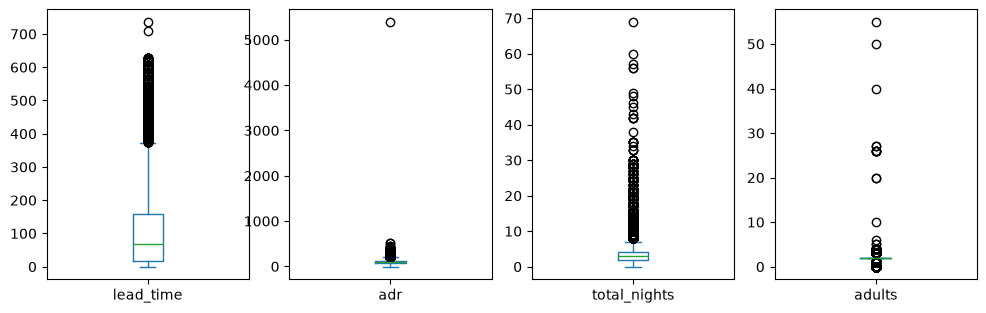

In [16]:
df[["lead_time", "adr", "total_nights", "adults"]].plot.box(subplots=True, figsize=(12, 3.5))
plt.show()

In [17]:
# число выбросов по правилу 1.5 * IQR
for col in ["lead_time", "adr", "total_nights"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(col, "- выбросов по IQR:", n_out)

lead_time - выбросов по IQR: 3005
adr - выбросов по IQR: 3793
total_nights - выбросов по IQR: 5257


Правило 1.5·IQR помечает тысячи строк, но для этих признаков **длинный правый хвост естественен**: бронь за год вперёд (`lead_time`) или отпуск на 2 недели (`total_nights`) — нормальные события, а не ошибки. Поэтому важнее искать **невозможные** значения:

In [18]:
df["adr"].nlargest(5)

48515    5400.00
111403    510.00
15083     508.00
103912    451.50
13142     450.00
Name: adr, dtype: float32

In [19]:
print("adr > 1000:", (df["adr"] > 1000).sum())
print("adults > 10:", (df["adults"] > 10).sum())
print("children >= 10:", (df["children"] >= 10).sum())
print("babies >= 9:", (df["babies"] >= 9).sum())
print("lead_time > 365:", (df["lead_time"] > 365).sum())
print("total_nights > 30:", (df["total_nights"] > 30).sum())

adr > 1000: 1
adults > 10: 12
children >= 10: 1
babies >= 9: 2
lead_time > 365: 3148
total_nights > 30: 24


**Явные аномалии:**

- **`adr = 5400`** — цена ночи в ~10 раз выше следующего максимума (~510). Почти наверняка ошибка ввода (лишний ноль или сумма за всё проживание).
- **`adults` от 20 до 55** в одной брони — вероятно, групповые брони, записанные одной строкой; для анализа «гостей в номере» это выбросы.
- **10 детей / 9–10 младенцев** в одной брони — единичные строки, скорее опечатки.
- **`lead_time` > 365 дней** (~3 тыс. строк, максимум 737) — правдоподобно для групп и событий, но требует внимания.

Эти строки немногочисленны: их стоит удалить или ограничить (winsorize), чтобы они не искажали средние и модели.

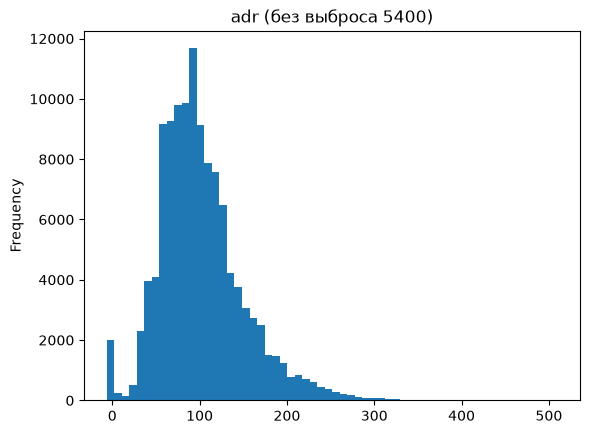

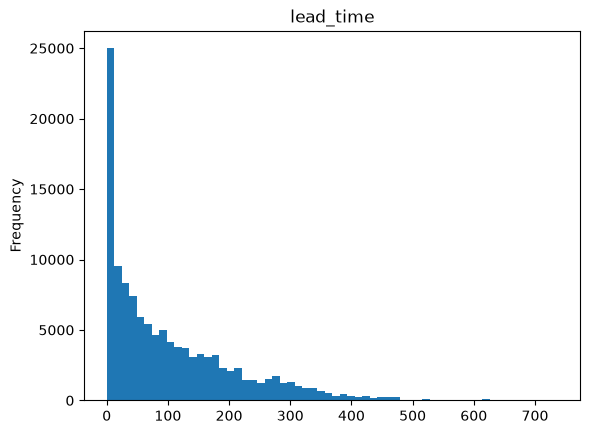

In [20]:
# распределение цены без экстремального значения
df[df["adr"] < 600]["adr"].plot.hist(bins=60, title="adr (без выброса 5400)")
plt.show()

df["lead_time"].plot.hist(bins=60, title="lead_time")
plt.show()

Обе гистограммы **скошены вправо**: большинство броней дешевле ~130 € и делаются менее чем за 160 дней. Для моделей такие признаки обычно логарифмируют.

## 6. Категориальные признаки

In [21]:
cat_cols = ["hotel", "meal", "market_segment", "distribution_channel",
            "deposit_type", "customer_type", "reservation_status"]
for col in cat_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts(normalize=True).mul(100).round(2).to_string())
    print()

--- hotel ---
hotel
City Hotel     66.45
Resort Hotel   33.55

--- meal ---
meal
BB          77.32
HB          12.11
SC           8.92
Undefined    0.98
FB           0.67

--- market_segment ---
market_segment
Online TA       47.30
Offline TA/TO   20.29
Groups          16.59
Direct          10.56
Corporate        4.44
Complementary    0.62
Aviation         0.20
Undefined        0.00

--- distribution_channel ---
distribution_channel
TA/TO       81.98
Direct      12.27
Corporate    5.59
GDS          0.16
Undefined    0.00

--- deposit_type ---
deposit_type
No Deposit   87.65
Non Refund   12.22
Refundable    0.14

--- customer_type ---
customer_type
Transient         75.06
Transient-Party   21.04
Contract           3.41
Group              0.48

--- reservation_status ---
reservation_status
Check-Out   62.96
Canceled    36.03
No-Show      1.01



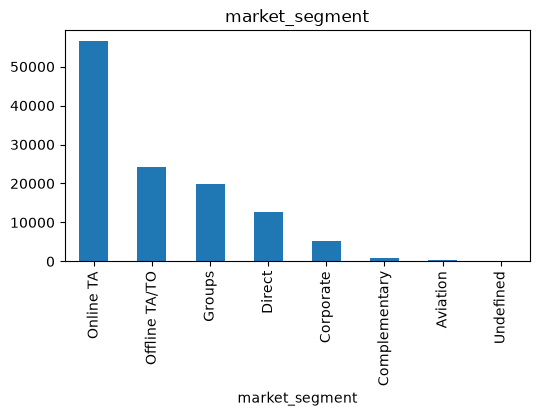

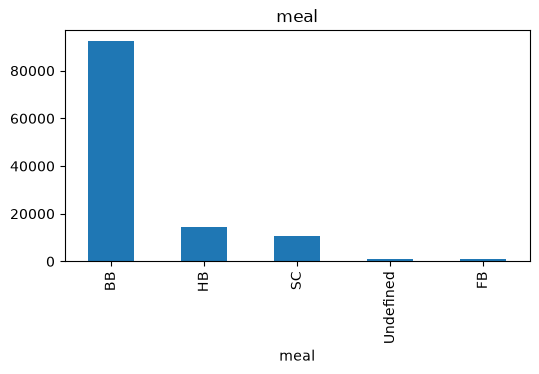

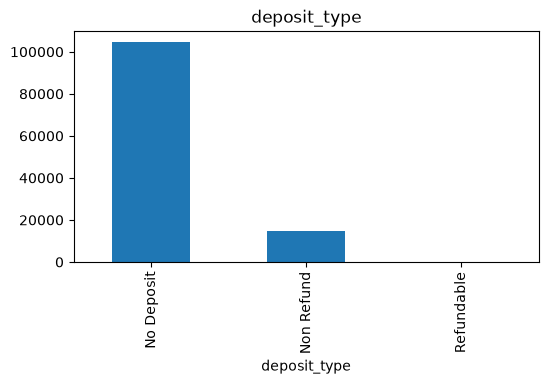

In [22]:
for col in ["market_segment", "meal", "deposit_type"]:
    df[col].value_counts().plot.bar(figsize=(6, 3), title=col)
    plt.show()

In [23]:
countries = df["country"].value_counts()
print("Стран:", df["country"].nunique())
print("Доля топ-5 стран, %:", round(countries.head(5).sum() / len(df) * 100, 1))
print("Стран с менее чем 10 бронями:", (countries < 10).sum())
countries.head(10)

Стран: 177
Доля топ-5 стран, %: 72.9
Стран с менее чем 10 бронями: 81


country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
Name: count, dtype: int64

**Наблюдения:**

- **Сильный дисбаланс категорий**: City Hotel — 2/3 данных; тип питания BB — ~77%; депозит No Deposit — ~88%; Refundable — всего 0.1%.
- **Редкие категории** (`Aviation`, `GDS`, `Undefined`, `Refundable`, тип номера `L`/`P`) — по несколько десятков строк и меньше, статистические выводы по ним ненадёжны.
- **Португалия — ~41% броней**, топ-5 стран дают ~73%, при этом десятки стран встречаются реже 10 раз — классический «длинный хвост», который при моделировании стоит объединять в «Other».
- **Подозрительная деталь**: среди `Non Refund` (невозвратный депозит) отменено **~99%** броней — это противоречит здравому смыслу и известно как особенность/артефакт этого датасета; такие данные стоит перепроверять у источника.

In [24]:
# проверка последнего тезиса
df.groupby("deposit_type", observed=True)["is_canceled"].agg(["mean", "size"])

,mean,size
deposit_type,,
No Deposit,0.28,104641
Non Refund,0.99,14587
Refundable,0.22,162


In [25]:
# забронированный и выданный тип номера
other_room = (df["reserved_room_type"].astype(str) != df["assigned_room_type"].astype(str)).mean()
print("Выдан не тот тип номера, %:", round(other_room * 100, 1))

Выдан не тот тип номера, %: 12.5


В ~12.5% броней выдан другой тип номера. Это не ошибка данных, а реальная практика отелей (апгрейд или замена), но для анализа это значит, что `reserved_room_type` и `assigned_room_type` — **разные признаки**, и путать их нельзя.

## 7. Корреляции

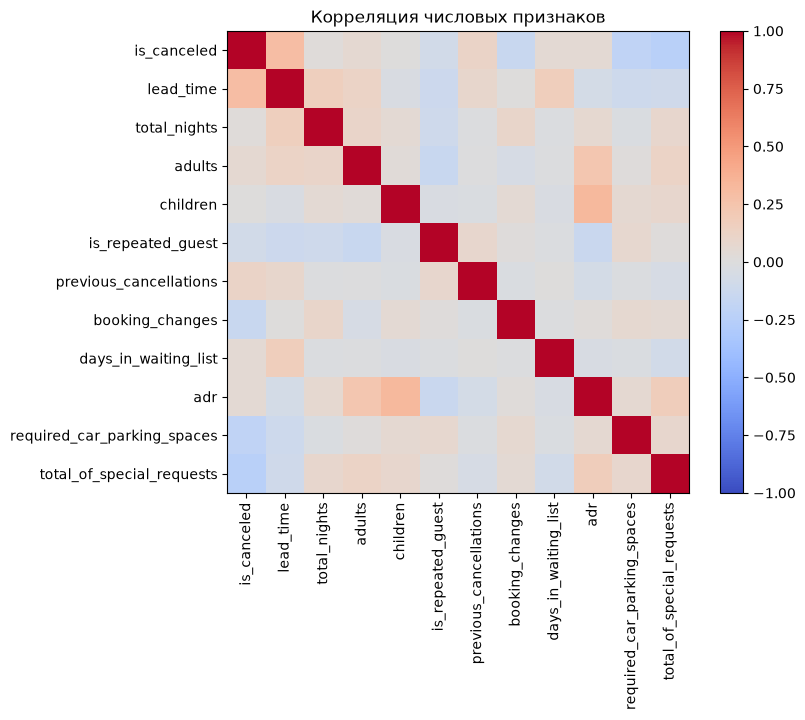

In [26]:
corr_cols = ["is_canceled", "lead_time", "total_nights", "adults", "children",
             "is_repeated_guest", "previous_cancellations", "booking_changes",
             "days_in_waiting_list", "adr", "required_car_parking_spaces",
             "total_of_special_requests"]
corr = df[corr_cols].astype(float).corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr_cols)), corr_cols, rotation=90)
plt.yticks(range(len(corr_cols)), corr_cols)
plt.colorbar()
plt.title("Корреляция числовых признаков")
plt.show()

In [27]:
corr["is_canceled"].drop("is_canceled").sort_values()

total_of_special_requests     -0.23
required_car_parking_spaces   -0.20
booking_changes               -0.14
is_repeated_guest             -0.08
children                       0.01
total_nights                   0.02
adr                            0.05
days_in_waiting_list           0.05
adults                         0.06
previous_cancellations         0.11
lead_time                      0.29
Name: is_canceled, dtype: float64

- Сильных корреляций между числовыми признаками **нет**: максимум |r| ≈ 0.32 (`children` и `adr` — с детьми берут номера дороже). Признаки не дублируют друг друга, мультиколлинеарность не грозит.
- С отменой сильнее всего связаны `lead_time` (+0.29: чем раньше бронь, тем чаще отмена), `total_of_special_requests` (−0.23) и `required_car_parking_spaces` (−0.20): гости с особыми пожеланиями и машиной отменяют реже.
- Коэффициент Пирсона ловит только линейные связи и чувствителен к выбросам (например, к `adr = 5400`), поэтому результаты — ориентир, а не окончательный вывод.

## 8. Метрики качества данных

In [28]:
n = len(df)
quality = pd.DataFrame({
    "метрика": [
        "Полнота (ячейки без NaN)",
        "Полнота без столбца company",
        "Уникальность строк",
        "Валидность: гостей > 0",
        "Валидность: adr ≥ 0 и ≤ 1000",
        "Валидность: ночей > 0",
        "Согласованность is_canceled ↔ reservation_status",
        "Согласованность номера недели с ISO",
    ],
    "значение_%": [
        df.notna().mean().mean() * 100,
        df.drop(columns="company").notna().mean().mean() * 100,
        (1 - df.duplicated().mean()) * 100,
        (df["total_guests"] > 0).mean() * 100,
        df["adr"].between(0, 1000).mean() * 100,
        (df["total_nights"] > 0).mean() * 100,
        (df["is_canceled"] == df["reservation_status"].isin(["Canceled", "No-Show"])).mean() * 100,
        (week_diff == 0).mean() * 100,
    ],
})
quality

,метрика,значение_%
0,Полнота (ячейки без NaN),96.90
1,Полнота без столбца company,99.59
2,Уникальность строк,73.20
3,Валидность: гостей > 0,99.85
4,Валидность: adr ≥ 0 и ≤ 1000,100.00
5,Валидность: ночей > 0,99.40
6,Согласованность is_canceled ↔ reservation_status,100.00
7,Согласованность номера недели с ISO,46.35


**Как читать метрики:**

- **Полнота** высокая (~97%), а без `company` — почти 100%: пропуски сосредоточены в одном столбце.
- **Уникальность ~73%** — главная проблема датасета (раздел 4.1).
- **Валидность** по основным правилам > 99%: невозможных значений мало, их можно точечно убрать.
- **Согласованность** статусов — 100%, а **номер недели** согласован с ISO меньше чем у половины строк (~46%) — признак ненадёжен.

## 9. Выводы

**Общая оценка.** Датасет **хорошего качества и пригоден для анализа**: структура понятная, типы признаков разнообразные, явных пропусков мало и они в основном содержательные, ключевые поля (статусы, даты) согласованы между собой. Основные проблемы локальны и устранимы.

**Найденные проблемы:**

| Проблема | Масштаб | Рекомендация |
|---|---|---|
| Полные дубликаты, нет ID брони | ~32 тыс. строк (27%) | Не удалять вслепую; решение зависит от задачи, уточнить у источника |
| `company` почти пустой | 94% | Заменить флагом «есть компания» |
| Пропуски в `agent` | 13.7% | Категория `no_agent` |
| `meal`: `Undefined` = `SC` | 1 169 строк | Объединить в одну категорию |
| Брони без гостей / на 0 ночей / без взрослых | 180 / 715 / 223 строки | Удалить или проверить |
| `adr = 0` вне сегмента Complementary | 1 279 строк | Проверить у источника |
| `Non Refund`: отменено ~99% броней | 14.6 тыс. строк | Перепроверить смысл категории у источника |
| Аномальные значения: `adr = 5400`, `adr < 0`, 20–55 взрослых, 10 детей | единицы строк | Удалить / ограничить |
| `arrival_date_week_number` не совпадает с ISO | ~54% строк | Пересчитать из даты |
| Неполные 2015 и 2017 годы | — | Не сравнивать годы целиком |
| Дисбаланс и редкие категории, «длинный хвост» стран | — | Группировать редкие значения в `Other` |
| `reservation_status` дублирует `is_canceled` | — | Исключать из признаков при моделировании отмен (утечка) |

На основе этих выводов можно написать функцию очистки (обработка пропусков, объединение категорий, удаление невалидных строк) и добавить её в пайплайн после `convert_types`.